# Chart encoding checks for the hotel bookings dashboard

**Data sources:** `data/processed/hotel_bookings_clean.csv` (Part 1) and `data/processed/country_names.csv` (Part 3), from Antonio, de Almeida and Nunes (2019).
**Date:** 2026-11-05
**Authors:** Group 3, Presentation and Visualization (Infovis2627)
**Description:** Evidence for Part 4 (tasks 4.1 and 4.2): the cardinality of every field we plan to encode, the DRACO hard-rule check of every planned chart, and the contrast and colour-blindness checks of the colours. No dashboard chart is built here; that is Part 6.

---

## Contents

1. [Data loading](#1.-Data-loading)
2. [Initial exploration: cardinalities](#2.-Initial-exploration:-cardinalities)
3. [Cleaning and preparation](#3.-Cleaning-and-preparation)
4. [Analysis: DRACO hard rules and colour checks](#4.-Analysis:-DRACO-hard-rules-and-colour-checks)
5. [Accessible visualisation: the palette](#5.-Accessible-visualisation:-the-palette)
6. [Export](#6.-Export)
7. [Conclusions](#Conclusions)

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

CLEAN_FILE   = Path('../../data/processed/hotel_bookings_clean.csv')
NAMES_FILE   = Path('../../data/processed/country_names.csv')
OUTPUT_DIR   = Path('encoding_checks_output')
IMAGES_DIR   = Path('../images')
OUTPUT_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 8})
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__,
      '| matplotlib', matplotlib.__version__)

Python 3.13.18 | pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2


## 1. Data loading

In [2]:
# ── Load the cleaned bookings and the country names ──────────────────────────
bookings = pd.read_csv(CLEAN_FILE, keep_default_na=False)
names = pd.read_csv(NAMES_FILE, keep_default_na=False)
bookings = bookings.merge(names[['country', 'country_name']], on='country', how='left')
bookings['arrival_date'] = pd.to_datetime(bookings['arrival_date'])
print(f'Rows: {len(bookings):,} | bookings without a country name: {bookings["country_name"].isna().sum()}')

Rows: 119,201 | bookings without a country name: 0


## 2. Initial exploration: cardinalities

DRACO limits the number of categories per channel (for example at most 20 colours, at most 8 shapes, and at most 50 values on an axis), and the skills limit categorical colours to 7. These are the values each planned encoding would show.

In [3]:
# ── Number of distinct values per planned encoding ────────────────────────────
top_10_countries = bookings['country_name'].value_counts().head(10).index.tolist()
cardinality = pd.Series({
    'hotel (colour + line style)': bookings['hotel'].nunique(),
    'arrival month, timeline (x axis)': bookings['arrival_date'].dt.to_period('M').nunique(),
    'calendar month (x axis of Q3)': bookings['arrival_date'].dt.month.nunique(),
    'countries shown: top 10 + Other (y axis)': len(top_10_countries) + 1,
    'all countries with a name (map)': bookings['country_name'].nunique(),
}, name='distinct values')
print('Top 10 countries:', top_10_countries)
cardinality

Top 10 countries: ['Portugal', 'United Kingdom', 'France', 'Spain', 'Germany', 'Italy', 'Ireland', 'Belgium', 'Brazil', 'Netherlands']


hotel (colour + line style)                   2
arrival month, timeline (x axis)             26
calendar month (x axis of Q3)                12
countries shown: top 10 + Other (y axis)     11
all countries with a name (map)             178
Name: distinct values, dtype: int64

## 3. Cleaning and preparation

Nothing is cleaned: the data comes from the cleaning script of Part 1 and the lookup of Part 3.

## 4. Analysis: DRACO hard rules and colour checks

### 4.1 Planned charts and their encodings (decided in task 4.1)

In [4]:
# ── Planned charts ────────────────────────────────────────────────────────────
planned_charts = pd.DataFrame([
    dict(chart='C1 Guests per month', question='Q1', screen='Main', mark='line',
         x='arrival month (temporal)', y='guests of stays (quantitative, sum)', color='hotel (nominal, 2)',
         other='strokeDash = hotel; separate point layer with shape = hotel'),
    dict(chart='C2 Cancellation rate per month', question='Q5', screen='Main', mark='line',
         x='arrival month (temporal)', y='% bookings cancelled (quantitative)', color='hotel (nominal, 2)',
         other='strokeDash = hotel'),
    dict(chart='C3 Median price per month', question='Q7', screen='Main', mark='line',
         x='arrival month (temporal)', y='median price per night (quantitative)', color='hotel (nominal, 2)',
         other='strokeDash = hotel'),
    dict(chart='C4 Guests by country', question='Q2', screen='Detail', mark='bar',
         x='% of guests (quantitative)', y='country, top 10 + Other (nominal, 11)', color='none (one colour)',
         other='column facet = hotel (2)'),
    dict(chart='C5 Map of guests', question='Q2', screen='Detail (expand)', mark='geoshape',
         x='-', y='-', color='% of guests (quantitative, sequential)', other='country shape'),
    dict(chart='C6 Season of the selected country', question='Q3', screen='Detail', mark='line',
         x='calendar month (temporal, month unit)', y='% of the group\'s guests (quantitative)',
         color='group: selected country / all guests (nominal, 2)', other='strokeDash = group'),
    dict(chart='C7 Nights per country', question='Q4', screen='Detail (expand)', mark='bar',
         x='median nights (quantitative)', y='country, top 10 (nominal, 10)', color='none', other='-'),
    dict(chart='C8 Booking advance per country', question='Q6', screen='Detail (expand)', mark='bar',
         x='median lead time in days (quantitative)', y='country, top 10 (nominal, 10)', color='none', other='-'),
])
planned_charts

,chart,question,screen,mark,x,y,color,other
0,C1 Guests per month,Q1,Main,line,arrival month (temporal),"guests of stays (quantitative, sum)","hotel (nominal, 2)",strokeDash = hotel; separate point layer with ...
1,C2 Cancellation rate per month,Q5,Main,line,arrival month (temporal),% bookings cancelled (quantitative),"hotel (nominal, 2)",strokeDash = hotel
2,C3 Median price per month,Q7,Main,line,arrival month (temporal),median price per night (quantitative),"hotel (nominal, 2)",strokeDash = hotel
3,C4 Guests by country,Q2,Detail,bar,% of guests (quantitative),"country, top 10 + Other (nominal, 11)",none (one colour),column facet = hotel (2)
4,C5 Map of guests,Q2,Detail (expand),geoshape,-,-,"% of guests (quantitative, sequential)",country shape
5,C6 Season of the selected country,Q3,Detail,line,"calendar month (temporal, month unit)",% of the group's guests (quantitative),"group: selected country / all guests (nominal, 2)",strokeDash = group
6,C7 Nights per country,Q4,Detail (expand),bar,median nights (quantitative),"country, top 10 (nominal, 10)",none,-
7,C8 Booking advance per country,Q6,Detail (expand),bar,median lead time in days (quantitative),"country, top 10 (nominal, 10)",none,-


In [5]:
# ── DRACO hard rules (checklist of the skill), checked for every planned chart ─
def draco_hard_checks(chart):
    """Return the hard rules of the DRACO checklist that apply to the chart, and whether they pass."""
    checks = {}
    if chart['mark'] in ['bar', 'area']:
        checks['bars and areas include zero'] = 'pass (x scale from 0)'
        checks['no log scale with bars'] = 'pass (linear scale)'
        checks['bar not continuous on both x and y'] = 'pass (y is nominal)'
    if chart['mark'] in ['line', 'area']:
        checks['line has x and y'] = 'pass'
        checks['line not discrete on both x and y'] = 'pass (x temporal, y quantitative)'
    if 'nominal, 2' in chart['color']:
        checks['discrete colour with 20 categories or fewer'] = 'pass (2)'
        checks['colour and strokeDash use the same field on different channels (no channel used twice)'] = 'pass'
    if 'nominal, 11' in chart['y'] or 'nominal, 10' in chart['y']:
        checks['at most 50 categories on an axis (soft) / 12 nominal values (soft)'] = 'pass for 10; 11 with Other, just under the 12 limit' if 'nominal, 11' in chart['y'] else 'pass (10)'
    if 'column facet' in chart['other']:
        checks['column requires a discrete field and an x encoding'] = 'pass (hotel is nominal, x is set)'
    if chart['mark'] == 'geoshape':
        checks['DRACO'] = 'not covered: DRACO has no rules for maps (said so, not guessed)'
    checks['same field not on x and y'] = 'pass'
    checks['no stacking with mean or median'] = 'pass (no stacking)'
    checks['no size with nominal fields'] = 'pass (size not used)'
    if 'shape' in chart['other']:
        checks['shape only with point marks and at most 8 values'] = 'pass (shape on a separate point layer, 2 hotels)'
    return checks

draco_table = pd.concat({row['chart']: pd.Series(draco_hard_checks(row)) for _, row in planned_charts.iterrows()})
draco_table = draco_table.rename('result').rename_axis(['chart', 'hard rule']).reset_index()
print('Checks failed:', (~draco_table['result'].str.startswith(('pass', 'not covered'))).sum())
draco_table

Checks failed: 0


,chart,hard rule,result
0,C1 Guests per month,line has x and y,pass
1,C1 Guests per month,line not discrete on both x and y,"pass (x temporal, y quantitative)"
2,C1 Guests per month,discrete colour with 20 categories or fewer,pass (2)
3,C1 Guests per month,colour and strokeDash use the same field on di...,pass
4,C1 Guests per month,same field not on x and y,pass
5,C1 Guests per month,no stacking with mean or median,pass (no stacking)
6,C1 Guests per month,no size with nominal fields,pass (size not used)
7,C1 Guests per month,shape only with point marks and at most 8 values,"pass (shape on a separate point layer, 2 hotels)"
8,C2 Cancellation rate per month,line has x and y,pass
9,C2 Cancellation rate per month,line not discrete on both x and y,"pass (x temporal, y quantitative)"


**Finding:** every planned chart passes the DRACO hard rules that apply to it. Two points need care. The country axis has 11 values (top 10 + Other), just under DRACO's soft limit of 12 nominal values. The map (C5) is outside DRACO, which has no rules for maps; it is judged with the course's GeoHandout instead and is only a secondary chart behind an "expand" button.

One soft preference is not followed on purpose: DRACO penalises lines when x is discrete. In C6 the month is used as a **time unit** (temporal), not as a category, and the course recommends lines for evolution over time (Visual Vocabulary, Gestalt continuity).

### 4.2 Colour checks

The palette is the list of hex colours given in the skills. The skills call it "Wong", but its values are Paul Tol's **"bright"** qualitative scheme (blue `#4477AA`, red `#EE6677`, green `#228833`, yellow `#CCBB44`, cyan `#66CCEE`, purple `#AA3377`, grey `#BBBBBB`), so that is the name used in our documents. The two hotels use blue and purple; one dark blue is used for single-colour bars; the focus ring is `#0066CC` (wcag-accessibility skill).

In [6]:
# ── Contrast ratio against a white background (WCAG 2.2) ─────────────────────

def linear_rgb(hex_colour):
    """sRGB hex colour -> linear RGB values between 0 and 1."""
    rgb = np.array([int(hex_colour[i:i + 2], 16) for i in (1, 3, 5)]) / 255
    return np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)


def relative_luminance(hex_colour):
    red, green, blue = linear_rgb(hex_colour)
    return 0.2126 * red + 0.7152 * green + 0.0722 * blue


def contrast_ratio(colour_1, colour_2='#FFFFFF'):
    lighter, darker = sorted([relative_luminance(colour_1), relative_luminance(colour_2)], reverse=True)
    return (lighter + 0.05) / (darker + 0.05)


dashboard_colours = {
    'City Hotel line (Tol blue)': '#4477AA',
    'Resort Hotel line (Tol purple)': '#AA3377',
    'Single-colour bars (dark blue)': '#1F4E79',
    'Focus ring': '#0066CC',
    'Secondary text (axis labels, source)': '#595959',
    'Main text (titles, values)': '#1A1A1A',
}
contrast_table = pd.DataFrame({'hex': dashboard_colours})
contrast_table['contrast on white'] = [round(contrast_ratio(h), 2) for h in contrast_table['hex']]
contrast_table['needed'] = ['3:1 (graphics)'] * 4 + ['4.5:1 (text)'] * 2
contrast_table['pass'] = [ratio >= (3 if need.startswith('3') else 4.5)
                          for ratio, need in zip(contrast_table['contrast on white'], contrast_table['needed'])]
contrast_table

,hex,contrast on white,needed,pass
City Hotel line (Tol blue),#4477AA,4.70,3:1 (graphics),True
Resort Hotel line (Tol purple),#AA3377,6.09,3:1 (graphics),True
Single-colour bars (dark blue),#1F4E79,8.66,3:1 (graphics),True
Focus ring,#0066CC,5.57,3:1 (graphics),True
"Secondary text (axis labels, source)",#595959,7.00,4.5:1 (text),True
"Main text (titles, values)",#1A1A1A,17.40,4.5:1 (text),True


In [7]:
# ── How the two hotel colours look with deuteranopia ─────────────────────────

# Simulation matrix of Machado, Oliveira and Fernandes (2009) for deuteranopia (severity 1.0),
# applied in linear RGB
DEUTERANOPIA = np.array([[0.367322, 0.860646, -0.227968],
                         [0.280085, 0.672501,  0.047413],
                         [-0.011820, 0.042940, 0.968881]])

def to_hex(linear):
    linear = np.clip(linear, 0, 1)
    srgb = np.where(linear <= 0.0031308, linear * 12.92, 1.055 * linear ** (1 / 2.4) - 0.055)
    return '#' + ''.join(f'{int(round(v * 255)):02X}' for v in srgb)


def to_lab(hex_colour):
    """CIE Lab (D65) of a hex colour, to measure how different two colours look (Delta E 1976)."""
    xyz = np.array([[0.4124, 0.3576, 0.1805], [0.2126, 0.7152, 0.0722], [0.0193, 0.1192, 0.9505]]) @ linear_rgb(hex_colour)
    xyz = xyz / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16 / 116)
    return np.array([116 * f[1] - 16, 500 * (f[0] - f[1]), 200 * (f[1] - f[2])])


def delta_e(colour_1, colour_2):
    return float(np.linalg.norm(to_lab(colour_1) - to_lab(colour_2)))


city, resort = '#4477AA', '#AA3377'
city_deut = to_hex(DEUTERANOPIA @ linear_rgb(city))
resort_deut = to_hex(DEUTERANOPIA @ linear_rgb(resort))
print(f'Normal vision: {city} vs {resort} -> Delta E {delta_e(city, resort):.1f}')
print(f'Deuteranopia:  {city_deut} vs {resort_deut} -> Delta E {delta_e(city_deut, resort_deut):.1f}')
print(f'Contrast between the two hotel colours: {contrast_ratio(city, resort):.2f}:1')

Normal vision: #4477AA vs #AA3377 -> Delta E 59.8
Deuteranopia:  #546FA9 vs #666A74 -> Delta E 28.8
Contrast between the two hotel colours: 1.29:1


**Finding:** both hotel colours, the bar colour, the focus ring and the text colours pass the WCAG 2.2 contrast minimums on white. Under simulated deuteranopia (Natalia's condition) the purple turns into a blue-grey, but the two hotels stay clearly different (Delta E 28.8, far above the usual just-noticeable difference of about 2.3, against 59.8 with normal vision). Their lightness, however, is close (contrast between them only 1.29:1). So colour is **never the only code**: each hotel also gets its own line style (solid / dashed), point shape (circle / square) and a direct text label at the end of its line (WCAG 1.4.1, Ware G5.11 redundant coding, Gestalt proximity of label and line).

## 5. Accessible visualisation: the palette

The swatches show the colours used in the dashboard as seen with normal vision and with simulated deuteranopia, with their hex code and contrast on white written under each one, so the figure itself does not depend on colour.

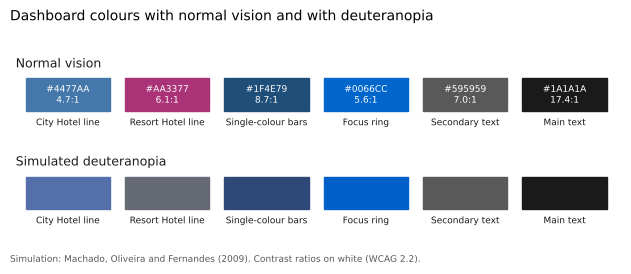

In [8]:
# ── Palette swatches: normal vision and simulated deuteranopia ───────────────
fig, axes = plt.subplots(2, 1, figsize=(6.3, 2.6))
for ax, (row_title, simulate) in zip(axes, [('Normal vision', False), ('Simulated deuteranopia', True)]):
    for position, (label, hex_colour) in enumerate(dashboard_colours.items()):
        shown = to_hex(DEUTERANOPIA @ linear_rgb(hex_colour)) if simulate else hex_colour
        ax.add_patch(plt.Rectangle((position, 0.35), 0.85, 0.6, color=shown))
        ax.text(position + 0.425, 0.22, label.split(' (')[0], ha='center', va='top', fontsize=6.5, color='#1A1A1A')
        if not simulate:
            ax.text(position + 0.425, 0.65, f'{hex_colour}\n{contrast_ratio(hex_colour):.1f}:1', ha='center',
                    va='center', fontsize=6.5, color='white' if contrast_ratio(hex_colour) > 4.5 else '#1A1A1A')
    ax.set_xlim(-0.1, len(dashboard_colours))
    ax.set_ylim(-0.25, 1)
    ax.set_title(row_title, loc='left', fontsize=9, color='#1A1A1A')
    ax.axis('off')
fig.suptitle('Dashboard colours with normal vision and with deuteranopia', x=0.01, ha='left', fontsize=10)
fig.text(0.01, 0.01, 'Simulation: Machado, Oliveira and Fernandes (2009). Contrast ratios on white (WCAG 2.2).',
         fontsize=6.5, color='#595959')
fig.tight_layout(rect=(0, 0.04, 1, 0.94))
fig.savefig(IMAGES_DIR / 'palette_check.png', dpi=200)
plt.show()

### 4.3 Accessibility plan, item by item

Every item of the accessibility list of `spec.md` and of the WCAG 2.2 AA + COGA checklist of the `wcag-accessibility` skill, with how the design answers it. "Part 6" means it is built and tested in the browser there; Part 4 decides only the design.

In [9]:
# ── Accessibility plan (design decisions; tested in Part 6) ──────────────────
P4, P5, P6 = 'designed (Part 4)', 'planned (Part 5)', 'built and tested (Part 6)'
accessibility_plan = pd.DataFrame([
    # Course guidelines (01-Introduction, low vision guidelines H1-H18)
    ('Course', 'Title, legend, axis titles, caption, abbreviations explained, data source (H1-H7)', P4, 'Every chart: plain-language title, axis titles with units, direct labels instead of legends, source and date in the footer, country names instead of ISO codes'),
    ('Course', 'Safe colours and contrast (H10-H11)', P4, 'Tol bright palette; contrast checked above (all pass)'),
    ('Course', 'Legibility and resize (H12, H14)', P4, 'Text at least 12 px in charts and 16 px in the page; layout works at 200 % zoom'),
    ('Course', 'Short alternative and long description (H8-H9)', P6, 'Each chart in a figure with a short and a long text alternative and a data table'),
    ('Course', 'Visible focus, device independence, customisation (H16-H18)', P5, 'Keyboard and mouse for every action; hotel filter; focus ring'),
    # Perception
    ('WCAG perception', 'Text contrast 4.5:1, graphics and UI 3:1', P4, 'Checked in section 4.2'),
    ('WCAG perception', 'Colour is never the only code', P4, 'Hotels: colour + line style + point shape + label; selected country: colour + outline + text'),
    ('WCAG perception', 'Text alternative for each chart', P6, 'figcaption with sr-only short and long text'),
    ('WCAG perception', 'SVG renderer only', P6, 'vega-embed with renderer svg'),
    ('WCAG perception', 'Reduced motion respected', P6, 'prefers-reduced-motion CSS; no animation in charts'),
    ('Pattern rules', 'Fill patterns when colour encodes categories', P4, 'No chart fills areas by category (bars use one colour; hotels are lines), so no fill patterns are needed; the map is quantitative and not a heatmap'),
    # Operability
    ('WCAG operability', 'Every data point reachable with the arrow keys; Alt + up/down between series', P5, 'Lines: points per month; two series (hotels) or (country / all)'),
    ('WCAG operability', 'Visible focus on every control and an SVG focus overlay on data points', P6, 'Overlay pattern of the skill'),
    ('WCAG operability', 'Selected category and exact value always visible next to the chart', P4, 'A "selected" text line above each chart'),
    ('WCAG operability', 'Previous / Next buttons disabled at the ends', P5, 'For the country selection'),
    ('WCAG operability', 'Touch / click targets at least 24 x 24 px (44 recommended)', P4, 'Buttons and selectors 44 px high'),
    ('WCAG operability', 'Skip link; no change of context on focus', P6, 'Skip link first in each page'),
    ('WCAG operability', 'Controls fit on mobile', 'adapted', 'Not applicable: desktop only (architecture.md); minimum width 1280 px'),
    # Comprehensibility
    ('WCAG comprehensibility', 'Labels for every control; state changes announced (aria-live)', P5, 'Filter and selection changes announced'),
    ('WCAG comprehensibility', 'Page language declared', P6, 'html lang="en"'),
    ('WCAG comprehensibility', 'Data in an external file, not in the HTML', 'adapted', 'data.js loaded with script src instead of data.json (architecture.md, opens by double-click)'),
    ('WCAG comprehensibility', 'Plain-language titles; numbers with thousands separators and units', P4, 'Titles as questions or statements; tooltips formatted'),
    ('WCAG comprehensibility', 'Active filters always visible; reset button always visible', P4, 'Filter panel with "Showing: ..." line and Reset button'),
    ('WCAG comprehensibility', 'At most 4 KPIs and 2-3 charts visible at once', P4, 'Main: 4 KPIs, 3 charts. Detail: 4 KPIs, 2 charts + 3 behind "Show more"'),
    ('WCAG comprehensibility', 'Icons always with a text label; legends fixed and not truncated', P4, 'Direct labels; no icon-only buttons'),
    ('WCAG comprehensibility', 'Errors describe what happened and how to fix it', P6, 'Message when a filter leaves no data'),
    # Robustness and help
    ('WCAG robustness', 'Valid HTML; correct ARIA; SVG with role="img" and aria-label; 200 % zoom', P6, 'Checked in the browser'),
    ('Help page', 'accessibility.html linked from both screens, with keys, filters, shortcuts and a contact', P6, 'Link next to the skip link'),
], columns=['source', 'item', 'status', 'how'])
accessibility_plan['status'].value_counts()

status
designed (Part 4)            12
built and tested (Part 6)    10
planned (Part 5)              4
adapted                       2
Name: count, dtype: int64

**Finding:** the design answers every item. Two items are adapted by decisions already in `architecture.md` (no mobile layout; data in `data.js`), and no fill patterns are needed because colour never fills areas by category. Items about behaviour are planned in Part 5 and tested in Part 6.

## 6. Export

In [10]:
# ── Export ────────────────────────────────────────────────────────────────────
cardinality.to_csv(OUTPUT_DIR / 'cardinality.csv')
planned_charts.to_csv(OUTPUT_DIR / 'planned_charts.csv', index=False)
draco_table.to_csv(OUTPUT_DIR / 'draco_hard_rules.csv', index=False)
contrast_table.to_csv(OUTPUT_DIR / 'contrast_checks.csv')
accessibility_plan.to_csv(OUTPUT_DIR / 'accessibility_plan.csv', index=False)
sorted(p.name for p in OUTPUT_DIR.iterdir())

['accessibility_plan.csv',
 'cardinality.csv',
 'contrast_checks.csv',
 'draco_hard_rules.csv',
 'planned_charts.csv']

## Conclusions

### Main findings
1. All eight planned charts pass the DRACO hard rules that apply to them; the map is outside DRACO and is kept as a secondary chart.
2. All dashboard colours pass the WCAG contrast minimums; the two hotel colours stay different with deuteranopia but are close in lightness, so line style, point shape and direct labels are added.

### Limitations
- The deuteranopia simulation is a model; the final check is done in the browser in Part 6.

### Suggested next steps
- Task 4.3: low-fidelity prototype of both screens.